# **Autonomous Merchant Grouping Engine (AMGE)**
### **Smart Transaction Enrichment Pipeline**

## **Project Overview**

### **Objective**
Convert raw transaction descriptions into normalized text and group transactions that belong to the same merchant, while preserving distinctions between merchant roots and sub-brands.

### **Pipeline at a glance**
1. **Structural normalization** - standardize raw transaction strings.
2. **Compound token normalization** - discover and split selected concatenated tokens.
3. **Hybrid feature space** - combine character n-gram TF-IDF features and SentenceTransformer embeddings.
4. **Distance matrix** - calculate pairwise cosine distances.
5. **Adaptive clustering** - select a clustering threshold using the existing silhouette-score search.
6. **Merchant root discovery and consolidation** - extract roots and assign unified cluster IDs.
7. **Feedback and Bayesian audit** - iteratively refine the existing pipeline and summarize cluster confidence.

## **Environment and Dependencies**

The following cell contains the notebook's existing imports and dependency setup. Run it before executing the pipeline.

In [23]:
import pandas as pd
import numpy as np
import re
import seaborn as sns
from collections import Counter
import matplotlib.pyplot as plt
from scipy.stats import beta
from scipy.sparse import csr_matrix, hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_distances
from sklearn.preprocessing import normalize
from sentence_transformers import SentenceTransformer

## **Input Data**

The current notebook uses an in notebook list of transaction descriptions as its demonstration dataset. The following cell creates the input DataFrame.

In [24]:
raw_txns = [
    "AMAZON MUMBAI IN", "UPI-CRED GIFTCARD", "AMAZON INDIA CYBS SI MUMBAI IN", "UPI-CRED", "SWIGGY GURGAON IN", "UPI-SWIGGY", "AMAZON PAY INDIA PVT L WWW.AMAZON.IN IND", "PRINCIPAL CREDIT ADJ",
    "AMAZON GURGAON IN", "AMAZON PRIME4R2LM9185 AMAMZN.CO.UK/PM...", "UPI-Swiggy Limited", "UPI-Apple Services", "Amazon Prime Membership amzn.com/prme WA", "CREDIT BALANCE REFUND CLOSED CARD-0813",
    "Swiggy Food Bangalore KA", "AMAZON MUMBAI MAH", "Swiggy Limited Bangalore IN", "GOOGLE VNG SINGAPORE g.co/helppay#CA", "AMAZON IN BILL PAYMENT MUMBAI IND", "ANNUAL FEE CREDIT ADJUSTMENT", "WWW AMAZON IN GURGAON IND", "AMAZON MUMBAI IND",
    "Swiggy Limited Bengaluru IN", "MARUTI INSURANCE NATIKOLKATTA IND", "AMAZON PRIME MEMBERSHI TOKYO JPN", "UPI-Amazon India", "Airindia South West Dein", "AMAZON WALLET LOAD MUMBAI IN", "AMAZON GIFT CARD MUMBAI IND",
    "AGGREGATOR EMI - OFFUS CREDIT", "Amazon Seller Services PrKARNATAKA IN", "AMAZON SELLER SERVICES MUMBAI IND", "Amazon.ca Prime Member amazon.ca/priBC", "AMZN UTILITIES MUMBAI IND", "MARUTI INSURANCE SBI GEMUMBAI IND",
    "SWIGGY LIMITED Bengaluru IN", "PayUSwiggy Limited Bangalore KAR", "AMAZON PAY INDIA PRIVA Bangalore IND", "UPI-ARCHANA MARUTI HIVAR", "AMAZON MKTPLNS2P80ZI3 Amzn.com/billWA", "SWIGGY IN BANGALORE IN",
    "UPI-APPLE SHOPPING MALL AC", "INTEREST CREDIT ADJ", "CRED MUMBAI IN", "UPI-Swiggy Diners", "CRED TELECOM MUMBAI IND", "APPLE INDIA PVT LTD PUNE IN", "SWIGGY BANGALORE IND", "AMZAvis Rent a Car pay.amazon.coNJ",
    "WWW SWIGGY COM GURGAON IN", "PTMSWIGGY IN BANGALORE KAR", "MARUTI INSURANCE ROYAL CHENNAI IND", "Cred Mumbai IN", "UPI-CREDPAYSWIGGY1", "SWIGGY GURGOAN hrIN", "LINKEDIN Singapore SG", "APPLE PLANET CARE BENGALURU IND",
    "AIRINDIABSP IN NEW DELHI IND", "PYUSwiggy Food Bangalore IND", "WWW SWIGGY IN BANGALORE IND", "AMAZON GIFT CARD MUMBAI IN", "Amazon web services aws.amazon.coWA", "SWIGGY DINEOUT BENGALURU IN", "CashfreeSWIGGY LIMITE Bengaluru KAR",
    "APPLE SHOPPING MALL MADURAI IND", "M-AMAZON SELLER SERVIC, P:01,000071790259", "Amazon Pay India Priva Bangalore Ind", "AIRINDIAWINR BARODA IN", "Amazon Prime2G3CT9W00 Amzn.com/bill WA", "MARUTI INSURANCE ROYA CHENNAI TAM",
    "INDAIR IA LTD (INR WWW.AIRINDIA.IN)", "AMAZON WEB SERVICES MUMBAI IN", "SWIGGY BENGALURU IN", "GOOGLE ADS4949671103 Singapore SGP", "Amazon Prime7J93E9SX3 Amzn.com/billWA", "Amazon.ae Dubai AE",
    "AIR INDIA LTD BARODA GUJ", "GOOGLE ADS4949671103 Singapore SGP", "Amazon Prime7J93E9SX3 Amzn.com/billWA", "Amazon.ae Dubai AE", "AIR INDIA LTD BARODA GUJ", "CRED GURGAON IND", "AMAZON RECHARGES MUMBAI IND",
    "SWIGGY FOOD BANGALORE KA", "Add_TajHotel_AirIndia_rev", "AMAZON MUMBAI IND", "CRED UTILITIES MUMBAI MHIN", "CREDIT CARD PAYMENT URSE", "CRED TELECOM BANGALORE IND", "CRED FASTAG MUMBAI IND",
    "AMAZON MARKETING SERVICES MUMBAI IN", "GENSPARK.AI SINGAPORE SG", "AMAZONIA CAFE BKC MUMBAI", "POS AMAZONIA RESTAURANT MUMBAI", "UPI-AMAZONIA CAFE", "AMAZONIA HOSPITALITY PVT LTD MUMBAI", "WWW AMAZONIA CAFE INDIA"
]

df = pd.DataFrame(raw_txns, columns=['txn_desc'])
print(f"Total Transactions Description: {len(df)}")




# df = pd.read_csv("transactions.csv")

# raw_txns = df["txn_desc"].dropna().astype(str).tolist()

# print(f"Total descriptions: {len(raw_txns)}")

Total Transactions Description: 97


### **Initial data preview**

Inspect the raw transaction descriptions before preprocessing. The next cell is the existing preview cell.

In [25]:
df.head()

,txn_desc
0,AMAZON MUMBAI IN
1,UPI-CRED GIFTCARD
2,AMAZON INDIA CYBS SI MUMBAI IN
3,UPI-CRED
4,SWIGGY GURGAON IN


## **Layer 1 - Structural Normalization**

This stage applies the existing regular expression preprocessing function to 

1. lowercase descriptions
2. remove URLs
3. remove special characters
4. remove long numeric identifiers
5. normalize whitespace

The original transaction description remains available in `txn_desc`; the cleaned representation is stored in `clean_txn`.

In [26]:
def safe_preprocess_text(text):
    text = text.lower()
    text = re.sub(r'(https?://|www\.)[^\s]+', ' ', text)
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    text = re.sub(r'\b\d{5,}\b', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_txn'] = df['txn_desc'].apply(safe_preprocess_text)
print("Layer 1 Updated: Pure Structural Normalization Active (0% Manual Lists).")

Layer 1 Updated: Pure Structural Normalization Active (0% Manual Lists).


### **Normalization preview**

Review the cleaned transaction text before compound token processing.

In [27]:
df.head()

,txn_desc,clean_txn
0,AMAZON MUMBAI IN,amazon mumbai in
1,UPI-CRED GIFTCARD,upi cred giftcard
2,AMAZON INDIA CYBS SI MUMBAI IN,amazon india cybs si mumbai in
3,UPI-CRED,upi cred
4,SWIGGY GURGAON IN,swiggy gurgaon in


## **Layer 2 - Compound Token Normalization**

This layer identifies and splits concatenated tokens using corpus-level frequency patterns. The `dynamic_split_compounds` function detects potential merchant names embedded within merged tokens and separates them into meaningful components (e.g., `payuswiggy` → `payu swiggy`), enabling more effective merchant identification without relying on manually predefined merchant dictionaries.

In [28]:
def dynamic_split_compounds(df, text_col='clean_txn'):

    def split_numbers(text):
        text = re.sub(r'([a-z]{3,})(\d+)', r'\1 \2', text)
        return re.sub(r'(\d+)([a-z]{3,})', r'\1 \2', text)

    df[text_col] = df[text_col].apply(split_numbers)

    all_tokens = " ".join(df[text_col]).split()
    token_counts = Counter(all_tokens)

    corpus_roots = sorted(
        [token for token, count in token_counts.items() if len(token) >= 4 and count >= 2],
        key=len,
        reverse=True
    )

    def split_embedded_roots(text):
        tokens = text.split()
        new_tokens = []
        for t in tokens:
            split_applied = False
            if len(t) > 7:
                for root in corpus_roots:
                    if root in t and t != root:
                        idx = t.find(root)
                        if idx > 0:
                            prefix = t[:idx]
                            suffix = t[idx:]
                            new_tokens.extend([prefix, suffix])
                            split_applied = True
                            break
            if not split_applied:
                new_tokens.append(t)
        return " ".join(new_tokens)

    df[text_col] = df[text_col].apply(split_embedded_roots)
    return df

df = dynamic_split_compounds(df, text_col='clean_txn')
print(" Layer 2 Complete: 100% Unsupervised Compound Token Splitter Ready.")

 Layer 2 Complete: 100% Unsupervised Compound Token Splitter Ready.


### **Token normalization preview**

Inspect the text after the existing compound-token stage.

In [29]:
df.head()

,txn_desc,clean_txn
0,AMAZON MUMBAI IN,amazon mumbai in
1,UPI-CRED GIFTCARD,upi cred gift card
2,AMAZON INDIA CYBS SI MUMBAI IN,amazon india cybs si mumbai in
3,UPI-CRED,upi cred
4,SWIGGY GURGAON IN,swiggy gurgaon in


## **Layers 3&4 - Hybrid Feature Space and Distance Matrix**

This layer combines character level `TF-IDF` features and SentenceTransformer embeddings to represent transaction descriptions using both lexical and semantic information. Character n-grams (3-5) capture merchant name patterns and spelling variations, while the `SBERT model` generates 384 dimensional semantic embeddings. Before feature extraction, dynamically discovered noise tokens are filtered using the current noise mask.

$$
X_{\text{hybrid}} =
\operatorname{normalize}
\left(
0.80 * X_{\text{char}} \,\Vert\, 0.20 * X_{\text{SBERT}}
\right)
$$

The normalized feature representations are then combined using a weighted approach, with a character feature weight of 0.80 and a semantic feature weight of 0.20. Finally, cosine distances are calculated between the hybrid representations to generate the distance matrix used by the adaptive clustering stage.

In [ ]:
if 'sbert_model' not in globals():
    print("Initializing SentenceTransformer model ('all-MiniLM-L6-v2')...")
    sbert_model = SentenceTransformer('all-MiniLM-L6-v2')

def lower_layer_extract_features(df, text_col='clean_txn', noise_mask=set()):
    def mask_tokens(text):
        tokens = [w for w in text.split() if w not in noise_mask and len(w) > 1]
        return " ".join(tokens) if tokens else text

    df['masked_txn'] = df[text_col].apply(mask_tokens)

    char_vectorizer = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5))
    X_char = char_vectorizer.fit_transform(df['masked_txn'])
    X_char_norm = normalize(X_char, norm='l2', axis=1)

    X_sbert = sbert_model.encode(df['masked_txn'].tolist(), show_progress_bar=False, convert_to_numpy=True)
    X_sbert_norm = normalize(X_sbert, norm='l2', axis=1)

    alpha = 0.80
    X_hybrid = hstack([X_char_norm.multiply(alpha), csr_matrix(X_sbert_norm * (1 - alpha))]).tocsr()
    X_hybrid = normalize(X_hybrid, norm='l2', axis=1)

    dist_matrix = cosine_distances(X_hybrid)

    return df, dist_matrix

print(" Layer 3 & 4 Complete: Lower Layer Parameter Receiver Ready.")

 Layer 3&4 Complete: Lower Layer Parameter Receiver Ready.


## **Layer 5 - Adaptive Agglomerative Clustering**

This layer applies Agglomerative Hierarchical Clustering with average linkage to group transactions based on their pairwise cosine distances. An adaptive threshold search evaluates multiple distance thresholds within a defined range and selects the configuration that achieves the highest Silhouette Score. 

$$
s = \frac{b-a}{\max(a,b)}
$$

where:
- $a$ = mean distance between a sample and other samples in the same cluster.
- $b$ = mean distance between a sample and samples in the nearest neighboring cluster.

The Silhouette Score measures cluster separation and cohesion, helping identify well separated groups without requiring a predefined number of clusters. The resulting cluster assignments are stored in `raw_cluster_id` and `cluster_id` for subsequent merchant root discovery and cluster consolidation.

In [31]:
def middle_layer_cluster(df, dist_matrix):
    best_score = -1
    best_threshold = 0.25
    best_labels = None

    for threshold in np.linspace(0.12, 0.38, 15):
        model = AgglomerativeClustering(
            n_clusters=None,
            metric='precomputed',
            linkage='average',
            distance_threshold=threshold
        )
        labels = model.fit_predict(dist_matrix)
        n_clusters = len(set(labels))

        if 1 < n_clusters < len(df):
            score = silhouette_score(dist_matrix, labels, metric='precomputed')
            if score > best_score:
                best_score = score
                best_threshold = threshold
                best_labels = labels

    if best_labels is None:
        best_labels = np.zeros(len(df), dtype=int)

    df['raw_cluster_id'] = best_labels
    df['cluster_id'] = best_labels
    return df

print(" Layer 5 Updated: Pure Clustering Engine Ready (Hard-split constraint removed).")

 Layer 5 Updated: Pure Clustering Engine Ready (Hard-split constraint removed).


## **Layer 6 - Merchant root discovery and consolidation**

### **6.1 - Statistical Merchant Root Discovery**

This stage identifies candidate merchant roots and sub brand signatures using token level statistics and graph based measures. 

The `Candidate Brand Successor Ratio` identifies operational prefixes by analyzing how frequently tokens precede different merchant names. 

and `Cross-Brand Entropy` helps identify generic tokens shared across multiple merchants.

while `Graph Modularity (ΔQ)` measures token associations to distinguish meaningful merchant patterns.

These signals are used to extract canonical merchant roots while preserving statistically significant sub-brands. The resulting root information is passed to the cluster consolidation and feedback stages.

**Example:**

`maruti insurance royal chennai ind` → `maruti insurance`

In [ ]:
def extract_primary_merchant_roots(df, text_col='resolved_masked_txn'):

    if text_col not in df.columns:
        text_col = 'masked_txn'

    all_txns = [t.split() for t in df[text_col] if t]

    index_zero_counts = Counter()
    token_total_counts = Counter()
    first_word_successors = {}

    for tokens in all_txns:
        first = tokens[0]
        index_zero_counts[first] += 1
        for t in tokens:
            token_total_counts[t] += 1

        if len(tokens) >= 2:
            if first not in first_word_successors:
                first_word_successors[first] = []
            first_word_successors[first].append(tokens[1])

    candidate_brands = {w for w, c in index_zero_counts.items() if c >= 2}

    dynamic_operational_prefixes = set()
    for prefix, successors in first_word_successors.items():
        brand_successors = {s for s in successors if s in candidate_brands and s != prefix}
        index_zero_ratio = index_zero_counts[prefix] / token_total_counts[prefix]

        if len(brand_successors) >= 2 and index_zero_ratio >= 0.70:
            dynamic_operational_prefixes.add(prefix)

    modifier_to_parents = {}
    for tokens in all_txns:
        clean_tokens = [t for t in tokens if t not in dynamic_operational_prefixes]
        if len(clean_tokens) >= 2:
            parent, modifier = clean_tokens[0], clean_tokens[1]
            if modifier not in modifier_to_parents:
                modifier_to_parents[modifier] = set()
            modifier_to_parents[modifier].add(parent)

    edge_weights = Counter()
    degree_counts = Counter()

    for tokens in all_txns:
        clean_tokens = [t for t in tokens if t not in dynamic_operational_prefixes]
        for i in range(len(clean_tokens)):
            degree_counts[clean_tokens[i]] += 1
            for j in range(i + 1, min(i + 3, len(clean_tokens))):
                pair = tuple(sorted([clean_tokens[i], clean_tokens[j]]))
                edge_weights[pair] += 1

    total_edges = sum(edge_weights.values()) if edge_weights else 1

    processed_records = []

    for tokens in all_txns:
        clean_tokens = [t for t in tokens if t not in dynamic_operational_prefixes]

        if not clean_tokens:
            processed_records.append(("UNKNOWN", []))
            continue

        parent = clean_tokens[0]

        if len(clean_tokens) >= 2:
            modifier = clean_tokens[1]
            pair = tuple(sorted([parent, modifier]))

            w_ij = edge_weights.get(pair, 0)                         ## How often does a pair of tokens appear together
            k_i = degree_counts[parent]                              ## How often does an individual token appear
            k_j = degree_counts[modifier]                            ## How often does an individual token appear

            expected_weight = (k_i * k_j) / (2 * total_edges)
            delta_Q = (w_ij - expected_weight) / (2 * total_edges) if total_edges > 0 else 0

            distinct_parents_for_modifier = len(modifier_to_parents.get(modifier, set()))

            if delta_Q > 0.0005 and w_ij >= 2 and distinct_parents_for_modifier < 2:
                primary_root = f"{parent} {modifier}"
                secondary_tokens = clean_tokens[2:]
            else:
                primary_root = parent
                secondary_tokens = clean_tokens[1:]
        else:
            primary_root = parent
            secondary_tokens = []

        processed_records.append((primary_root, secondary_tokens))

    df['merchant_root_data'] = processed_records
    return df

print(" Layer 6.1 Upgraded: Cross-Brand Entropy Guardrail Active.")

 Layer 6.1 Upgraded: Cross-Brand Entropy Guardrail Active.


### **6.2 - Canonical Cluster Consolidation**

This stage consolidates independent distance based clusters that share the same primary merchant root or extracted sub brand signature. It uses the structured merchant root information generated in Stage 6.1 to map each unique root to a canonical cluster ID, reducing over segmentation caused by variations in transaction locations and terminal suffixes. The consolidation process aims to group transactions belonging to the same merchant while preserving distinctions between separate commercial entities, such as `AMAZON` and `AMAZONIA CAFE`.

**Example:**

- `AMAZON MUMBAI IN` → Root: `AMAZON` → Cluster 0
- `AMAZON GURGAON IN` → Root: `AMAZON` → Cluster 0
- `AMAZON PRIME MEMBERSHIP` → Root: `AMAZON PRIME` → Cluster 5

In [33]:
def consolidate_merchant_clusters(df):
    df = extract_primary_merchant_roots(df, text_col='masked_txn')

    root_to_cluster = {}
    curr_id = 0
    unified_ids = []

    for root, _ in df['merchant_root_data']:
        if root not in root_to_cluster:
            root_to_cluster[root] = curr_id
            curr_id += 1
        unified_ids.append(root_to_cluster[root])

    df['cluster_id'] = unified_ids
    return df

print(" Layer 6.2 Updated: Sub-Brand Cluster Consolidator Ready.")

 Layer 6.2 Updated: Sub-Brand Cluster Consolidator Ready.


## **Layer 7 - Feedback and Bayesian audit**

### **7.1 - Feedback Controller and Final Merchant Assignment**

This stage implements an iterative feedback mechanism that refines merchant grouping through recursive noise discovery and feedback optimization. The controller identifies generic tokens shared across different merchant clusters and feeds the discovered noise tokens back into the feature extraction process to improve subsequent clustering results. During each iteration, feature extraction, clustering, merchant root discovery, cluster consolidation, and quality-score evaluation are repeated. The process terminates when no new noise tokens are discovered or the change in the quality score falls below the threshold of 0.001. Once the stopping condition is met, the controller returns `final_df` containing the final cluster assignments and mined merchant names.

In [ ]:
def score_driven_feedback_controller(
    df,
    text_col='clean_txn',
    active_noise_mask=set(),
    prev_silhouette=-1.0,
    pass_depth=1,
    min_score_delta=0.001
):
    print(f"PASS {pass_depth} :- ")
    print(f"Active Discovered Noise Rules ({len(active_noise_mask)}): {sorted(list(active_noise_mask))}")

    df, dist_matrix = lower_layer_extract_features(df, text_col=text_col, noise_mask=active_noise_mask)

    df = middle_layer_cluster(df, dist_matrix)

    df = extract_primary_merchant_roots(df, text_col='masked_txn')

    root_to_cluster = {}
    curr_id = 0
    unified_ids = []
    for root, _ in df['merchant_root_data']:
        if root not in root_to_cluster:
            root_to_cluster[root] = curr_id
            curr_id += 1
        unified_ids.append(root_to_cluster[root])
    df['cluster_id'] = unified_ids

    labels = df['cluster_id'].values
    num_clusters = len(set(labels))

    if 1 < num_clusters < len(df):
        current_silhouette = silhouette_score(dist_matrix, labels, metric='precomputed')
    else:
        current_silhouette = 0.0

    score_delta = current_silhouette - prev_silhouette
    print(f"Formed {num_clusters} Unified Merchant Clusters | Silhouette Score: {current_silhouette:.4f} (ΔS: {score_delta:+.4f})")

    immune_tokens = set()                                       ## Stores tokens that are protected from being discovered as noise.
    for root, _ in df['merchant_root_data']:
        if root != "UNKNOWN":
            immune_tokens.update(root.lower().split())

    token_brand_map = {}                                      ## measures how many different merchant roots use a token, eg. {'mumbai': {'amazon', 'swiggy', 'cred'}}
    for _, (primary_root, secondary_tokens) in zip(df.index, df['merchant_root_data']):
        for t in secondary_tokens:
            if t not in token_brand_map:
                token_brand_map[t] = set()
            token_brand_map[t].add(primary_root)

    new_discovered_rules = {                                                      ## token is discovered as noise
        token for token, brands in token_brand_map.items()
        if len(brands) >= 3                                                       ## It appears as a secondary token under at least three distinct merchant roots.
        and token not in active_noise_mask                                        ## It is not already present in the active noise mask.
        and token not in immune_tokens                                            ## It is not part of a protected merchant root.
    }

    if not new_discovered_rules:
        print("TERMINATION: Rule set converged. No new noise tokens detected.")
        should_terminate = True
    elif pass_depth > 1 and score_delta < min_score_delta:                        ## The silhouette score has stopped improving
        print(f"TERMINATION: Silhouette Score plateaued (ΔS = {score_delta:+.4f} < {min_score_delta}).")
        should_terminate = True
    else:
        should_terminate = False

    if not should_terminate:
        print(f"NEW NOISE RULES MINED: {new_discovered_rules}")
        print("--> Back-propagating rules to Cell 4...\n")

        updated_noise_mask = active_noise_mask.union(new_discovered_rules)

        return score_driven_feedback_controller(
            df,
            text_col=text_col,
            active_noise_mask=updated_noise_mask,
            prev_silhouette=current_silhouette,
            pass_depth=pass_depth + 1,
            min_score_delta=min_score_delta
        )
    else:
        print("\nOPTIMAL CONVERGENCE ACHIEVED! Pipeline Locked.")

        globals()['dist_matrix'] = dist_matrix

        cluster_to_merchant = {}
        for c_id, group in df.groupby('cluster_id'):                                                    
            roots = [root for root, _ in group['merchant_root_data'] if root != "UNKNOWN"]                      ## Collects the merchant roots within each cluster
            top = Counter(roots).most_common(1)[0][0].upper() if roots else "UNKNOWN"                           ## Counts how often each root appears
            cluster_to_merchant[c_id] = top                                                                     ## Selects the most frequent root.

        df['mined_merchant'] = df['cluster_id'].map(cluster_to_merchant)                                        ## final merchant name column
        return df

final_df = score_driven_feedback_controller(df, text_col='clean_txn')

PASS 1 :- 
Active Discovered Noise Rules (0): []
Formed 40 Unified Merchant Clusters | Silhouette Score: 0.1406 (ΔS: +1.1406)
NEW NOISE RULES MINED: {'ltd', 'card', 'com', 'singapore', 'services', 'pvt', 'mumbai', 'gurgaon', 'india', 'in', 'ind', 'kar'}
--> Back-propagating rules to Cell 4...

PASS 2 :- 
Active Discovered Noise Rules (12): ['card', 'com', 'gurgaon', 'in', 'ind', 'india', 'kar', 'ltd', 'mumbai', 'pvt', 'services', 'singapore']
Formed 41 Unified Merchant Clusters | Silhouette Score: 0.1995 (ΔS: +0.0590)
TERMINATION: Rule set converged. No new noise tokens detected.

OPTIMAL CONVERGENCE ACHIEVED! Pipeline Locked.


### **Final Result Preview**

Inspect a sample of the final transaction level output produced by the existing controller.

In [35]:
final_df.head()

,txn_desc,clean_txn,masked_txn,raw_cluster_id,cluster_id,merchant_root_data,mined_merchant
0,AMAZON MUMBAI IN,amazon mumbai in,amazon,4,0,"(amazon, [])",AMAZON
1,UPI-CRED GIFTCARD,upi cred gift card,upi cred gift,0,1,"(cred, [gift])",CRED
2,AMAZON INDIA CYBS SI MUMBAI IN,amazon india cybs si mumbai in,amazon cybs si,37,0,"(amazon, [cybs, si])",AMAZON
3,UPI-CRED,upi cred,upi cred,3,1,"(cred, [])",CRED
4,SWIGGY GURGAON IN,swiggy gurgaon in,swiggy,2,2,"(swiggy, [])",SWIGGY


### **Cluster Level Inspection**

This stage examines the generated merchant clusters by displaying their assigned merchant names, cluster sizes, and associated transaction descriptions. It helps assess grouping consistency, verify merchant root assignments, and identify potential over merging or fragmentation across clusters.

In [36]:
print(f"=================================================================")
print(f"       FULL MERCHANT CLUSTER BREAKDOWN (Total: {final_df['cluster_id'].nunique()} Clusters)")
print(f"=================================================================\n")

for cluster_id, group in final_df.groupby('cluster_id'):
    merchant_title = group['mined_merchant'].iloc[0]
    txn_count = len(group)

    print(f"============ Cluster {cluster_id}: [{merchant_title}] ({txn_count} Transactions) ============")

    for idx, row in enumerate(group['txn_desc'], 1):
        print(f"  {idx}. {row}")

    print("\n")

       FULL MERCHANT CLUSTER BREAKDOWN (Total: 41 Clusters)

============ Cluster 0: [AMAZON] (15 Transactions) ============
  1. AMAZON MUMBAI IN
  2. AMAZON INDIA CYBS SI MUMBAI IN
  3. AMAZON GURGAON IN
  4. AMAZON MUMBAI MAH
  5. AMAZON IN BILL PAYMENT MUMBAI IND
  6. WWW AMAZON IN GURGAON IND
  7. AMAZON MUMBAI IND
  8. UPI-Amazon India
  9. AMAZON WALLET LOAD MUMBAI IN
  10. AMAZON GIFT CARD MUMBAI IND
  11. AMAZON MKTPLNS2P80ZI3 Amzn.com/billWA
  12. AMAZON GIFT CARD MUMBAI IN
  13. AMAZON RECHARGES MUMBAI IND
  14. AMAZON MUMBAI IND
  15. AMAZON MARKETING SERVICES MUMBAI IN


============ Cluster 1: [CRED] (7 Transactions) ============
  1. UPI-CRED GIFTCARD
  2. UPI-CRED
  3. CRED MUMBAI IN
  4. Cred Mumbai IN
  5. CRED GURGAON IND
  6. CRED UTILITIES MUMBAI MHIN
  7. CRED FASTAG MUMBAI IND


============ Cluster 2: [SWIGGY] (6 Transactions) ============
  1. SWIGGY GURGAON IN
  2. UPI-SWIGGY
  3. UPI-Swiggy Diners
  4. WWW SWIGGY COM GURGAON IN
  5. SWIGGY GURGOAN hrIN
  6. S

### **7.2 - Bayesian Cluster Audit**

This stage evaluates the quality and consistency of the generated merchant clusters using **Beta Binomial Bayesian inference** with a Beta(1, 1) prior. For each cluster, the audit estimates confidence using the observed number of matching transactions and the total cluster size, providing a posterior mean and a 95% credible interval to represent uncertainty. Based on the calculated confidence, each cluster is assigned an operational review category to support automated approval or prioritize manual validation. The audit results are stored in `eval_matrix_df`.

**Posterior Mean:**

$$
E[p \mid x,n] = \frac{x+1}{n+2}
$$

where:
- \(x\) = number of observed successful outcomes.
- \(n\) = total number of observations in the cluster.

In [ ]:
def compute_subbrand_aware_confidence(df, alpha_prior=1.0, beta_prior=1.0):

    eval_records = []                                                   ## stores one evaluation record for each merchant cluster

    for c_id, group in df.groupby("cluster_id"):
        mined_merchant = group["mined_merchant"].iloc[0]
        n = len(group)                                                  ## number of transactions in that cluster

        extracted_roots = [
            root for root, _ in group["merchant_root_data"] if root != "UNKNOWN"
        ]

        x = (                                                           ## number of observations matching the dominant root
            Counter(extracted_roots).most_common(1)[0][1] if extracted_roots else n
        )

        alpha_post = x + alpha_prior
        beta_post = (n - x) + beta_prior
        p_posterior_mean = alpha_post / (n + alpha_prior + beta_prior)

        confidence_pct = p_posterior_mean * 100.0

        ci_lower_pct = beta.ppf(0.025, alpha_post, beta_post) * 100.0
        ci_upper_pct = beta.ppf(0.975, alpha_post, beta_post) * 100.0

        if confidence_pct >= 80.0:
            admin_flag = "🟢 AUTO-APPROVE"
        elif confidence_pct >= 60.0:
            admin_flag = "🟡 LOW PRIORITY REVIEW"
        else:
            admin_flag = "🔴 HIGH PRIORITY REVIEW"

        eval_records.append(
            {
                "Cluster ID": c_id,
                "Mined Merchant": mined_merchant,
                "Cluster Size (n)": n,
                "Dominant Root Count (x)": x,
                "Bayesian Cluster Confidence (%)": round(confidence_pct, 2),
                "95% Credible Interval": f"[{ci_lower_pct:.1f}% - {ci_upper_pct:.1f}%]",
                "Operational Decision": admin_flag,
                "Sample Transaction": group["txn_desc"].iloc[0],
            }
        )

    eval_df = (
        pd.DataFrame(eval_records)
        .sort_values(by="Cluster Size (n)", ascending=False)
        .reset_index(drop=True)
    )
    eval_df.index = eval_df.index + 1  # 1-based indexing for easy row counting

    print("==================================================")
    print("📊 BAYESIAN CLUSTER EVALUATION & AUDIT REPORT")
    print("==================================================")
    print(f"Total Merchant Clusters              : {len(eval_df)}")
    print(
        f"Average Bayesian Cluster Confidence : {round(eval_df['Bayesian Cluster Confidence (%)'].mean(), 2)}%"
    )
    print("==================================================\n")

    return df, eval_df


final_df, eval_matrix_df = compute_subbrand_aware_confidence(final_df)
eval_df = (
    pd.DataFrame(eval_matrix_df)
    .sort_values(by="Cluster ID", ascending=True)
    .reset_index(drop=True)
)
display(eval_df)

📊 BAYESIAN CLUSTER EVALUATION & AUDIT REPORT
Total Merchant Clusters              : 41
Average Bayesian Cluster Confidence : 73.29%



,Cluster ID,Mined Merchant,Cluster Size (n),Dominant Root Count (x),Bayesian Cluster Confidence (%),95% Credible Interval,Operational Decision,Sample Transaction
0,0,AMAZON,15,15,94.12,[79.4% - 99.8%],🟢 AUTO-APPROVE,AMAZON MUMBAI IN
1,1,CRED,7,7,88.89,[63.1% - 99.7%],🟢 AUTO-APPROVE,UPI-CRED GIFTCARD
2,2,SWIGGY,6,6,87.50,[59.0% - 99.6%],🟢 AUTO-APPROVE,SWIGGY GURGAON IN
3,3,AMAZON PAY,3,3,80.00,[39.8% - 99.4%],🟢 AUTO-APPROVE,AMAZON PAY INDIA PVT L WWW.AMAZON.IN IND
4,4,PRINCIPAL,1,1,66.67,[15.8% - 98.7%],🟡 LOW PRIORITY REVIEW,PRINCIPAL CREDIT ADJ
5,5,AMAZON PRIME,6,6,87.50,[59.0% - 99.6%],🟢 AUTO-APPROVE,AMAZON PRIME4R2LM9185 AMAMZN.CO.UK/PM...
6,6,SWIGGY LIMITED,4,4,83.33,[47.8% - 99.5%],🟢 AUTO-APPROVE,UPI-Swiggy Limited
7,7,APPLE,3,3,80.00,[39.8% - 99.4%],🟢 AUTO-APPROVE,UPI-Apple Services
8,8,CREDIT,2,2,75.00,[29.2% - 99.2%],🟡 LOW PRIORITY REVIEW,CREDIT BALANCE REFUND CLOSED CARD-0813
9,9,SWIGGY FOOD,2,2,75.00,[29.2% - 99.2%],🟡 LOW PRIORITY REVIEW,Swiggy Food Bangalore KA


The engine evaluates internal cluster consistency using unsupervised quality metrics, without requiring manually labeled ground-truth data. Based on the calculated Bayesian confidence score, each merchant cluster is assigned an operational status to guide automated mapping and manual review.

- **AUTO-APPROVE (≥ 80%):** Clusters meeting the confidence threshold are eligible for automatic merchant mapping.
- **LOW PRIORITY (70%–79%):** Clusters are placed in a secondary review queue for further inspection, particularly for potential sub-brand variations.
- **HIGH PRIORITY (< 70%):** Clusters are flagged for manual validation due to higher uncertainty.

In [38]:
final_df.to_csv('cleaned_merchant_clusters.csv', index=False)
print("File saved as 'cleaned_merchant_clusters.csv'")

File saved as 'cleaned_merchant_clusters.csv'


In [39]:
check=pd.read_csv("cleaned_merchant_clusters.csv")

In [40]:
check.head(10)

,txn_desc,clean_txn,masked_txn,raw_cluster_id,cluster_id,merchant_root_data,mined_merchant
0,AMAZON MUMBAI IN,amazon mumbai in,amazon,4,0,"('amazon', [])",AMAZON
1,UPI-CRED GIFTCARD,upi cred gift card,upi cred gift,0,1,"('cred', ['gift'])",CRED
2,AMAZON INDIA CYBS SI MUMBAI IN,amazon india cybs si mumbai in,amazon cybs si,37,0,"('amazon', ['cybs', 'si'])",AMAZON
3,UPI-CRED,upi cred,upi cred,3,1,"('cred', [])",CRED
4,SWIGGY GURGAON IN,swiggy gurgaon in,swiggy,2,2,"('swiggy', [])",SWIGGY
5,UPI-SWIGGY,upi swiggy,upi swiggy,2,2,"('swiggy', [])",SWIGGY
6,AMAZON PAY INDIA PVT L WWW.AMAZON.IN IND,amazon pay india pvt l ind,amazon pay,61,3,"('amazon pay', [])",AMAZON PAY
7,PRINCIPAL CREDIT ADJ,principal credit adj,principal credit adj,42,4,"('principal', ['credit', 'adj'])",PRINCIPAL
8,AMAZON GURGAON IN,amazon gurgaon in,amazon,4,0,"('amazon', [])",AMAZON
9,AMAZON PRIME4R2LM9185 AMAMZN.CO.UK/PM...,amazon prime 4r2lm9185 amamzn co uk pm,amazon prime 4r2lm9185 amamzn co uk pm,31,5,"('amazon prime', ['4r2lm9185', 'amamzn', 'co',...",AMAZON PRIME


## **Visualization - Top Mined Merchant Distributions**

The existing chart displays the most frequent mined merchant labels and their transaction counts. Use it as a high level view of the current output distribution; it is not, by itself, a measure of clustering accuracy.

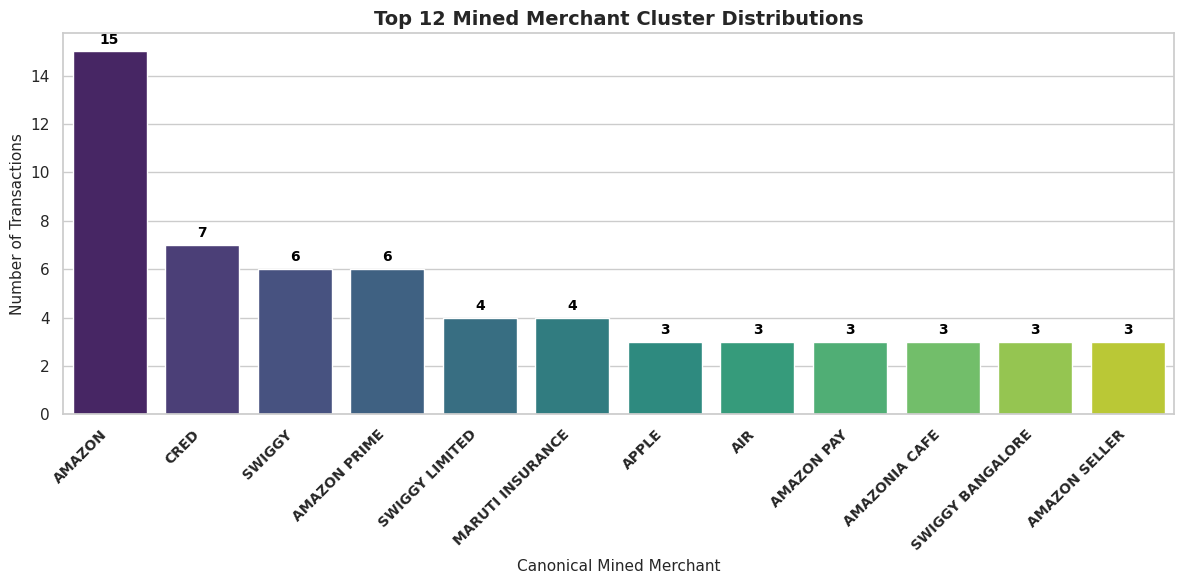

In [41]:
sns.set_theme(style="whitegrid", palette="muted")
plt.figure(figsize=(12, 6))

top_merchants = final_df['mined_merchant'].value_counts().head(12)

ax1 = sns.barplot(
    x=top_merchants.index,
    y=top_merchants.values,
    hue=top_merchants.index,
    palette="viridis",
    legend=False
)
plt.title("Top 12 Mined Merchant Cluster Distributions", fontsize=14, fontweight='bold')
plt.xlabel("Canonical Mined Merchant", fontsize=11)
plt.ylabel("Number of Transactions", fontsize=11)

plt.xticks(rotation=45, ha='right', fontsize=10, fontweight='bold')

for p in ax1.patches:
    height = p.get_height()
    ax1.annotate(
        f"{int(height)}",
        (p.get_x() + p.get_width() / 2., height + 0.2),
        ha='center', va='bottom', fontsize=10, color='black', fontweight='bold'
    )

plt.tight_layout()
plt.show()

## **Business Advantages**

- **Personalized Customer Engagement:** Enables personalized customer recommendations and targeted marketing campaigns based on merchant transaction patterns.
- **Merchant Analytics:** Supports merchant analytics for partnership opportunities, customer behavior insights, and informed business decision-making.
- **Emerging Merchant Discovery:** Identifies emerging merchants and new transaction patterns, supporting faster merchant onboarding and market expansion.